# ML Lab Mini Project: Diamond Price Prediction

**Dataset:** 53,940 diamonds with carat, cut, colour, clarity, depth, table and price.

**What this project does**
1. Explores and cleans the data
2. Predicts the **price** of a diamond (regression)
3. Classifies a diamond as **Budget / Mid / Premium** (classification)
4. Groups diamonds into **market segments** (clustering)
5. Gives a **live demo**: type any diamond, get its price and class

| Part | Method | Lab |
| --- | --- | --- |
| 1 | EDA, cleaning, encoding, scaling | Lab 1–2 |
| 2 | Linear Regression, Decision Tree, Random Forest | Lab 3, 7 |
| 3 | Logistic Regression, KNN, SVM, Decision Tree, Random Forest | Lab 4, 5, 6, 7 |
| 4 | K-Means clustering | Lab 8 |

Keep this notebook in the same folder as `diamonds.csv`, then click **Run All** (about a minute).

In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, f1_score, confusion_matrix,
                             classification_report, silhouette_score)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
BASE = os.getcwd()          # folder of this notebook

# Part 1: Data exploration and cleaning (Lab 1–2)

In [2]:
path = os.path.join(BASE, "diamonds.csv")
if os.path.exists(path):
    df = pd.read_csv(path)
else:                        # not in the folder -> download a copy (needs internet)
    df = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/diamonds.csv")
    df.to_csv(path, index=False)

print("Shape:", df.shape)
print("Missing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", df.duplicated().sum())
print("Rows with zero or impossible size:", int(((df.x == 0) | (df.y == 0) | (df.z == 0) | (df.y > 30) | (df.z > 30)).sum()))
df.head()

Shape: (53940, 10)
Missing values: 0
Duplicate rows: 146
Rows with zero or impossible size: 23


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [3]:
df.describe().round(2)

,carat,depth,table,price,x,y,z
count,53940.00,53940.00,53940.00,53940.00,53940.00,53940.00,53940.00
mean,0.80,61.75,57.46,3932.80,5.73,5.73,3.54
std,0.47,1.43,2.23,3989.44,1.12,1.14,0.71
min,0.20,43.00,43.00,326.00,0.00,0.00,0.00
25%,0.40,61.00,56.00,950.00,4.71,4.72,2.91
50%,0.70,61.80,57.00,2401.00,5.70,5.71,3.53
75%,1.04,62.50,59.00,5324.25,6.54,6.54,4.04
max,5.01,79.00,95.00,18823.00,10.74,58.90,31.80


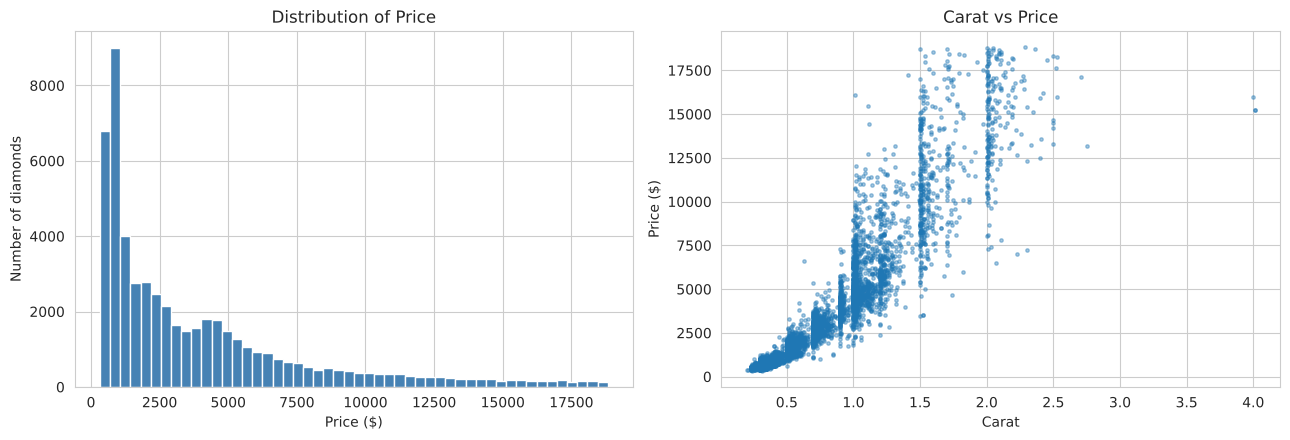

Price skewness: 1.62 (right-skewed: most diamonds are cheap)


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].hist(df["price"], bins=50, color="steelblue")
ax[0].set(title="Distribution of Price", xlabel="Price ($)", ylabel="Number of diamonds")
sample = df.sample(5000, random_state=42)
ax[1].scatter(sample["carat"], sample["price"], s=6, alpha=0.4)
ax[1].set(title="Carat vs Price", xlabel="Carat", ylabel="Price ($)")
plt.tight_layout()
plt.show()
print("Price skewness:", round(df["price"].skew(), 2), "(right-skewed: most diamonds are cheap)")

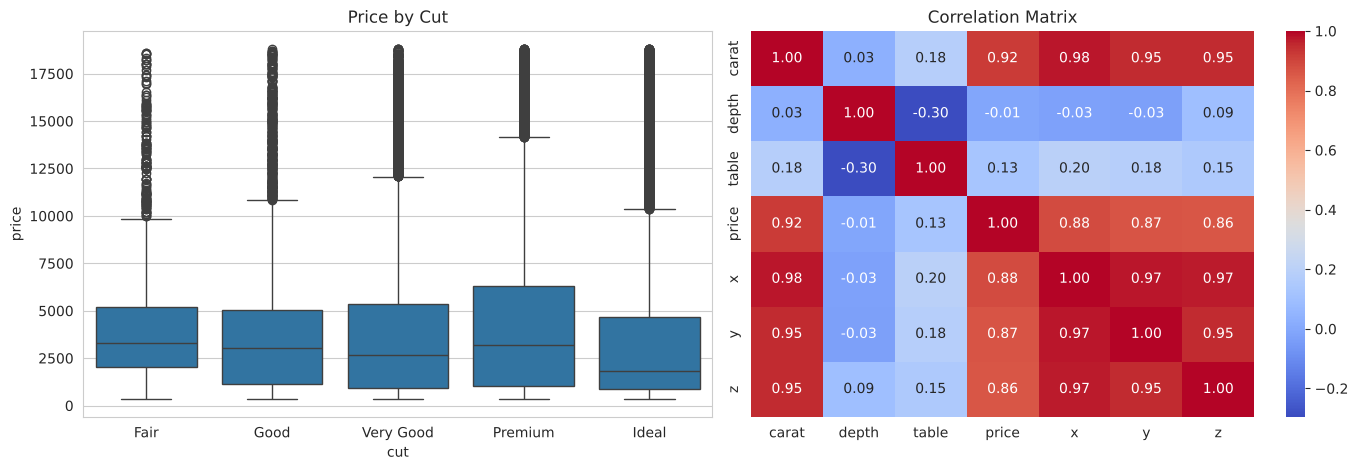

Median price and carat by cut:
            price  carat
cut                     
Fair       3282.0   1.00
Good       3050.5   0.82
Very Good  2648.0   0.71
Premium    3185.0   0.86
Ideal      1810.0   0.54


In [5]:
cut_order = ["Fair", "Good", "Very Good", "Premium", "Ideal"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
sns.boxplot(data=df, x="cut", y="price", order=cut_order, ax=ax[0])
ax[0].set_title("Price by Cut")
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1])
ax[1].set_title("Correlation Matrix")
plt.tight_layout()
plt.show()
print("Median price and carat by cut:")
print(df.groupby("cut")[["price", "carat"]].median().loc[cut_order])

In [6]:
# Cleaning
df = df.drop_duplicates()
df = df[(df.x > 0) & (df.y > 0) & (df.z > 0) & (df.y < 30) & (df.z < 30)]
print("Records after cleaning:", len(df))

# Ordinal encoding: these categories have a natural order (worst -> best)
orders = {"cut": ["Fair", "Good", "Very Good", "Premium", "Ideal"],
          "color": ["J", "I", "H", "G", "F", "E", "D"],
          "clarity": ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]}
for col, order in orders.items():
    df[col] = df[col].map({v: i for i, v in enumerate(order)})

# x, y, z are ~0.98 correlated with carat, so they are dropped
features = ["carat", "cut", "color", "clarity", "depth", "table"]
X = df[features]
y_price = df["price"]
y_class = pd.cut(df["price"], bins=[0, 1000, 5000, np.inf], labels=["Budget", "Mid", "Premium"])
print("Features used:", features)
print("\nPrice classes (Budget < $1,000, Mid $1,000-5,000, Premium > $5,000):")
print(y_class.value_counts().to_string())

Records after cleaning: 53772
Features used: ['carat', 'cut', 'color', 'clarity', 'depth', 'table']

Price classes (Budget < $1,000, Mid $1,000-5,000, Premium > $5,000):
price
Mid        24636
Premium    14666
Budget     14470


# Part 2: Predicting the price (Lab 3, 7)

In [7]:
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X, y_price, test_size=0.2, random_state=42)
scaler_r = StandardScaler().fit(Xr_train)
print("Training records:", len(Xr_train), "| Testing records:", len(Xr_test))

lin = LinearRegression().fit(scaler_r.transform(Xr_train), yr_train)
# Trees split on thresholds, so they do not need scaled features
dt_reg = DecisionTreeRegressor(max_depth=15, min_samples_leaf=10, random_state=42).fit(Xr_train, yr_train)
rf_reg = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1).fit(Xr_train, yr_train)

preds = {"Linear Regression": lin.predict(scaler_r.transform(Xr_test)),
         "Decision Tree": dt_reg.predict(Xr_test),
         "Random Forest": rf_reg.predict(Xr_test)}
reg_table = pd.DataFrame({name: {"MAE ($)": mean_absolute_error(yr_test, p),
                                 "RMSE ($)": np.sqrt(mean_squared_error(yr_test, p)),
                                 "R2": r2_score(yr_test, p)} for name, p in preds.items()}).T
print(reg_table.round(4).to_string())

Training records: 43017 | Testing records: 10755


                    MAE ($)   RMSE ($)      R2
Linear Regression  854.9923  1232.9079  0.9021
Decision Tree      307.6762   585.1660  0.9780
Random Forest      279.5707   536.1731  0.9815


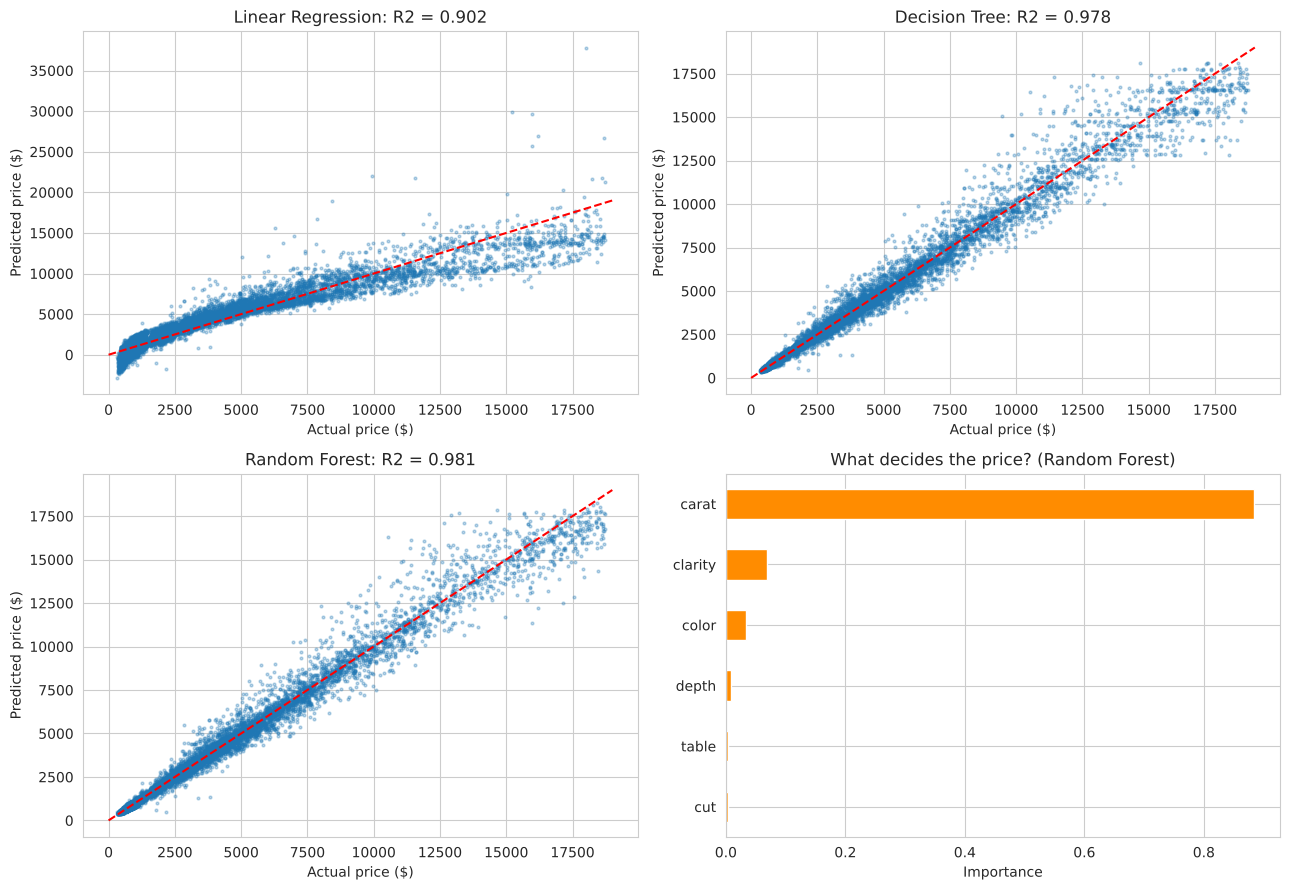

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
ax = ax.ravel()
for a, (name, p) in zip(ax[:3], preds.items()):
    a.scatter(yr_test, p, s=4, alpha=0.3)
    a.plot([0, 19000], [0, 19000], "r--")
    a.set(title=f"{name}: R2 = {r2_score(yr_test, p):.3f}", xlabel="Actual price ($)", ylabel="Predicted price ($)")
pd.Series(rf_reg.feature_importances_, index=features).sort_values().plot(kind="barh", ax=ax[3], color="darkorange")
ax[3].set(title="What decides the price? (Random Forest)", xlabel="Importance")
plt.tight_layout()
plt.show()

# Part 3: Classifying Budget / Mid / Premium (Lab 4, 5, 6, 7)

In [9]:
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X, y_class, test_size=0.2, random_state=42, stratify=y_class)
scaler_c = StandardScaler().fit(Xc_train)
Xc_train_s, Xc_test_s = scaler_c.transform(Xc_train), scaler_c.transform(Xc_test)

# Logistic Regression (Lab 4)
log_reg = LogisticRegression(max_iter=1000).fit(Xc_train_s, yc_train)

# KNN (Lab 5): scaling matters, and K is chosen with cross-validation
raw_acc = KNeighborsClassifier(n_neighbors=5).fit(Xc_train, yc_train).score(Xc_test, yc_test)
print(f"KNN (K=5) accuracy without scaling = {raw_acc:.4f}")
k_values = [3, 5, 7, 9, 11, 15, 21]
cv = [cross_val_score(KNeighborsClassifier(n_neighbors=k), Xc_train_s, yc_train, cv=3).mean() for k in k_values]
best_k = k_values[int(np.argmax(cv))]
print("CV accuracy for each K:", {k: round(float(v), 4) for k, v in zip(k_values, cv)}, "-> best K =", best_k)
knn = KNeighborsClassifier(n_neighbors=best_k).fit(Xc_train_s, yc_train)

KNN (K=5) accuracy without scaling = 0.7715


CV accuracy for each K: {3: 0.8825, 5: 0.8856, 7: 0.8861, 9: 0.8855, 11: 0.8873, 15: 0.8861, 21: 0.8877} -> best K = 21


In [10]:
# Decision Tree (Lab 7): a tree with no depth limit overfits
print("max_depth | Train accuracy | Test accuracy")
for d in [3, 5, 10, 15, None]:
    t = DecisionTreeClassifier(max_depth=d, random_state=42).fit(Xc_train, yc_train)
    print(f"{str(d):>9} | {t.score(Xc_train, yc_train):.4f}         | {t.score(Xc_test, yc_test):.4f}")

max_depth | Train accuracy | Test accuracy


        3 | 0.8667         | 0.8629


        5 | 0.9169         | 0.9154


       10 | 0.9528         | 0.9393


       15 | 0.9769         | 0.9295


     None | 0.9882         | 0.9252


In [11]:
# Train all five classifiers and compare them
models = {
    "Logistic Regression": (log_reg, True),
    "KNN": (knn, True),
    "SVM (RBF kernel)": (SVC(kernel="rbf", C=10, gamma="scale"), True),        # Lab 6
    "Decision Tree": (DecisionTreeClassifier(criterion="entropy", max_depth=10,
                                             min_samples_leaf=10, random_state=42), False),
    "Random Forest": (RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1), False),
}
rows = {}
for name, (m, scaled) in models.items():
    t0 = time.time()
    m.fit(Xc_train_s if scaled else Xc_train, yc_train)
    train_time = time.time() - t0
    p = m.predict(Xc_test_s if scaled else Xc_test)
    rows[name] = {"Accuracy": accuracy_score(yc_test, p), "F1-score": f1_score(yc_test, p, average="macro"),
                  "Train time (s)": train_time}
clf_table = pd.DataFrame(rows).T.sort_values("Accuracy", ascending=False)
print(clf_table.round(4).to_string())

                     Accuracy  F1-score  Train time (s)
Decision Tree          0.9398    0.9413          0.1165
SVM (RBF kernel)       0.9384    0.9398         10.1459
Random Forest          0.9336    0.9350          1.5939
Logistic Regression    0.9254    0.9270          0.1834
KNN                    0.8977    0.9001          0.1295


Best classifier: Decision Tree
              precision    recall  f1-score   support

      Budget     0.9160    0.9686    0.9416      2894
         Mid     0.9498    0.9172    0.9332      4928
     Premium     0.9486    0.9495    0.9491      2933

    accuracy                         0.9398     10755
   macro avg     0.9381    0.9451    0.9413     10755
weighted avg     0.9404    0.9398    0.9398     10755



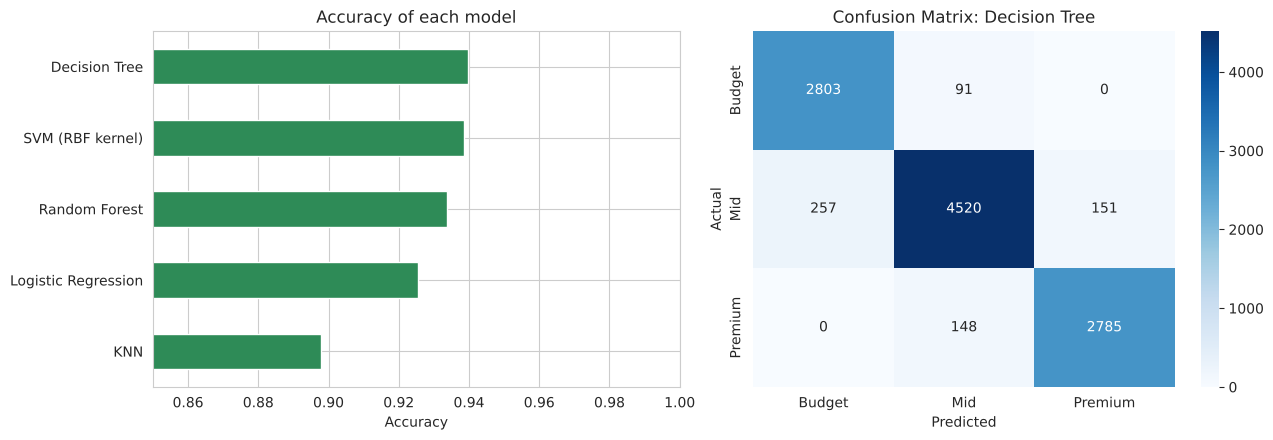

In [12]:
best_name = clf_table.index[0]
best_clf, best_scaled = models[best_name]
pred = best_clf.predict(Xc_test_s if best_scaled else Xc_test)
labels = ["Budget", "Mid", "Premium"]
print(f"Best classifier: {best_name}")
print(classification_report(yc_test, pred, digits=4))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
clf_table["Accuracy"].sort_values().plot(kind="barh", ax=ax[0], color="seagreen")
ax[0].set(title="Accuracy of each model", xlabel="Accuracy", xlim=(0.85, 1.0))
sns.heatmap(confusion_matrix(yc_test, pred, labels=labels), annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels, ax=ax[1])
ax[1].set(title=f"Confusion Matrix: {best_name}", xlabel="Predicted", ylabel="Actual")
plt.tight_layout()
plt.show()

# Part 4: Market segments with K-Means (Lab 8)

 K    WCSS  Silhouette
 2 37643.9      0.6070
 3 16362.6      0.6173
 4 11386.8      0.5642
 5  7996.9      0.5507
 6  6593.8      0.5296
 7  5616.6      0.5280
 8  4766.0      0.5215
Optimal K = 3

          Diamonds  Avg_carat  Avg_price        Segment name
Segment                                                    
2           31183       0.47    1370.41  Small & affordable
0           16659       1.08    5498.05              Medium
1            5930       1.75   12994.87      Large & luxury


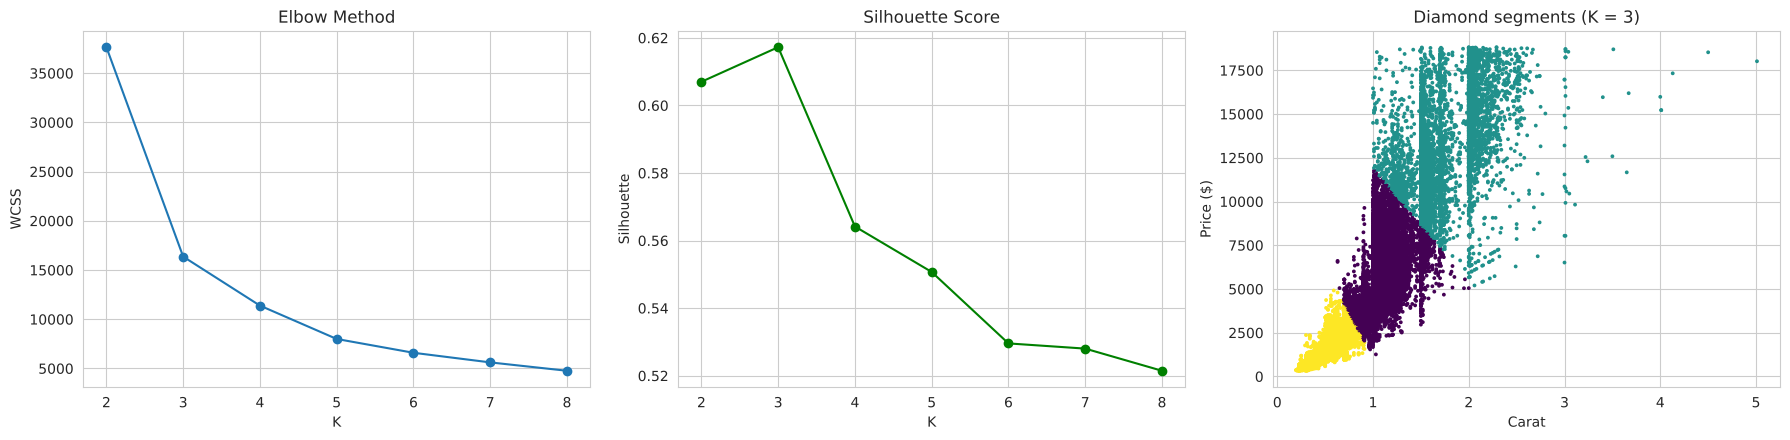

In [13]:
Z = StandardScaler().fit_transform(df[["carat", "price"]])
K_range = range(2, 9)
wcss, sil = [], []
for k in K_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    wcss.append(km.inertia_)
    sil.append(silhouette_score(Z, km.labels_, sample_size=10000, random_state=42))  # sample for speed
best_k_clusters = list(K_range)[int(np.argmax(sil))]
print(pd.DataFrame({"K": list(K_range), "WCSS": np.round(wcss, 1), "Silhouette": np.round(sil, 4)}).to_string(index=False))
print("Optimal K =", best_k_clusters)

kmeans = KMeans(n_clusters=best_k_clusters, n_init=10, random_state=42).fit(Z)
df["Segment"] = kmeans.labels_
seg = (df.groupby("Segment").agg(Diamonds=("price", "size"), Avg_carat=("carat", "mean"), Avg_price=("price", "mean"))
         .sort_values("Avg_price").round(2))
if len(seg) == 3:
    seg["Segment name"] = ["Small & affordable", "Medium", "Large & luxury"]
print("\n", seg.to_string())

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].plot(list(K_range), wcss, marker="o"); ax[0].set(title="Elbow Method", xlabel="K", ylabel="WCSS")
ax[1].plot(list(K_range), sil, marker="o", color="green"); ax[1].set(title="Silhouette Score", xlabel="K", ylabel="Silhouette")
ax[2].scatter(df["carat"], df["price"], c=kmeans.labels_, cmap="viridis", s=3)
ax[2].set(title=f"Diamond segments (K = {best_k_clusters})", xlabel="Carat", ylabel="Price ($)")
plt.tight_layout()
plt.show()

# Part 5: Live demo

In [14]:
def predict_diamond(carat, cut, color, clarity, depth=61.8, table=57.0):
    """Predicts the price and class of one diamond."""
    row = pd.DataFrame([{"carat": carat, "cut": orders["cut"].index(cut),
                         "color": orders["color"].index(color), "clarity": orders["clarity"].index(clarity),
                         "depth": depth, "table": table}])
    price = rf_reg.predict(row)[0]
    cls = best_clf.predict(scaler_c.transform(row) if best_scaled else row)[0]
    print(f"{carat} carat, {cut} cut, colour {color}, clarity {clarity} -> "
          f"predicted price = ${price:,.0f}, class = {cls}")


print(f"Best price model: Random Forest (R2 = {reg_table.loc['Random Forest', 'R2']:.4f})")
print(f"Best classifier : {best_name} (accuracy = {clf_table['Accuracy'].max():.4f})")

Best price model: Random Forest (R2 = 0.9815)
Best classifier : Decision Tree (accuracy = 0.9398)


Change the values below and run the cell again.
- cut: Fair, Good, Very Good, Premium, Ideal
- colour: J (worst) … D (best)
- clarity: I1 (worst), SI2, SI1, VS2, VS1, VVS2, VVS1, IF (best)

In [15]:
predict_diamond(carat=0.30, cut="Good", color="J", clarity="SI2")
predict_diamond(carat=1.00, cut="Ideal", color="G", clarity="VS1")
predict_diamond(carat=2.00, cut="Premium", color="D", clarity="IF")

0.3 carat, Good cut, colour J, clarity SI2 -> predicted price = $370, class = Budget
1.0 carat, Ideal cut, colour G, clarity VS1 -> predicted price = $6,568, class = Premium
2.0 carat, Premium cut, colour D, clarity IF -> predicted price = $17,127, class = Premium


In [16]:
# Optional: type your own diamond (remove the # from the lines below)
# carat = float(input("Carat: "))
# cut = input("Cut (Fair/Good/Very Good/Premium/Ideal): ")
# color = input("Colour (J to D): ")
# clarity = input("Clarity (I1, SI2, SI1, VS2, VS1, VVS2, VVS1, IF): ")
# predict_diamond(carat, cut, color, clarity)